## 1. Import libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from pathlib import Path
from textblob import TextBlob
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
pd.set_option("display.max_colwidth", 140)

DATA_FILE = Path("HelloPeter_Discovery_Health_Reviews_Sample.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError("Place HelloPeter_Discovery_Health_Reviews_Sample.csv beside this notebook.")
df = pd.read_csv(DATA_FILE)
print("Original dataset shape:", df.shape)
display(df.head())

Original dataset shape: (15, 8)


,Review_ID,Provider,Review_Date,Rating,Review_Title,Review_Text,Source_URL,Sentiment_Label
0,HP001,Discovery Health,2022-11-08,1,Discovery health is the worse medical aid,Incorrect benefit information; unpaid doctor account; repeated follow-ups; payment ultimately declined after staff reportedly acknowledg...,https://www.hellopeter.com/discovery-health/reviews/80-5744c2592e3ab37790379e32283079e2c65d717c-4170087,Negative
1,HP002,Discovery Health,2026-07-01,1,Customer help is waste of time,"A co-payment query is passed between chatbot, human agent and email without resolution; reviewer says they need accessible human assista...",https://www.hellopeter.com/discovery-health/reviews/customer-help-is-waste-of-time-6459081,Negative
2,HP003,Discovery Health,2026-09-16,1,No compassion worst of the worst,"Reviewer reports a hospital admission problem for a planned delivery, allegedly caused by communication breakdown, and poor coordination...",https://www.hellopeter.com/discovery-health/reviews/no-compassion-worst-of-the-worst-6600396,Negative
3,HP004,Discovery Health,2025-07-03,1,Chronic Nightmare,Reviewer complains about non-payment for chronic medication and unanswered emails and complaints.,https://www.hellopeter.com/discovery-health/reviews/chronic-nightmare-5819192,Negative
4,HP005,Discovery Health,2023-07-04,1,Leg not at full functionality,Reviewer says a follow-up procedure was excluded despite an earlier larger procedure being covered.,https://www.hellopeter.com/discovery-health/reviews/leg-not-at-full-functionality-4495981,Negative


## 2. Data cleaning
Check column names, data types, missing values, duplicates and review text.

In [2]:
df.columns = df.columns.str.strip()
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
df["Review_Date"] = pd.to_datetime(df["Review_Date"], errors="coerce")
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")
text_columns = ["Review_ID","Provider","Review_Title","Review_Text","Source_URL","Sentiment_Label"]
for col in text_columns:
    df[col] = df[col].fillna("").astype(str).str.strip()

print("Exact duplicate rows found:", duplicate_count)
print("\nMissing values:")
display(df.isna().sum().to_frame("Missing values"))
print("\nData types:")
display(df.dtypes.astype(str).to_frame("Data type"))
print("\nSentiment labels:")
display(df["Sentiment_Label"].value_counts(dropna=False).to_frame("Records"))
print("\nRatings:")
display(df["Rating"].value_counts(dropna=False).sort_index().to_frame("Records"))
df["Combined_Text"] = (df["Review_Title"] + " " + df["Review_Text"]).str.replace(r"\s+"," ",regex=True).str.strip()
df["Text_Word_Count"] = df["Combined_Text"].str.split().str.len()
print("Records after duplicate removal:", len(df))

Exact duplicate rows found: 0

Missing values:


,Missing values
Review_ID,0
Provider,0
Review_Date,0
Rating,0
Review_Title,0
Review_Text,0
Source_URL,0
Sentiment_Label,0



Data types:


,Data type
Review_ID,object
Provider,object
Review_Date,datetime64[ns]
Rating,int64
Review_Title,object
Review_Text,object
Source_URL,object
Sentiment_Label,object



Sentiment labels:


,Records
Sentiment_Label,
Negative,15



Ratings:


,Records
Rating,
1,13
2,2


Records after duplicate removal: 15


## 3. Exploratory data analysis (EDA)

Rows and columns: (15, 10)
Date range: 2015-08-18 to 2026-10-26
Mean rating: 1.13 out of 5


,Rating,Text_Word_Count
count,15.000000,15.000000
mean,1.133333,20.600000
std,0.351866,4.067291
min,1.000000,14.000000
25%,1.000000,17.500000
50%,1.000000,20.000000
75%,1.000000,24.500000
max,2.000000,26.000000


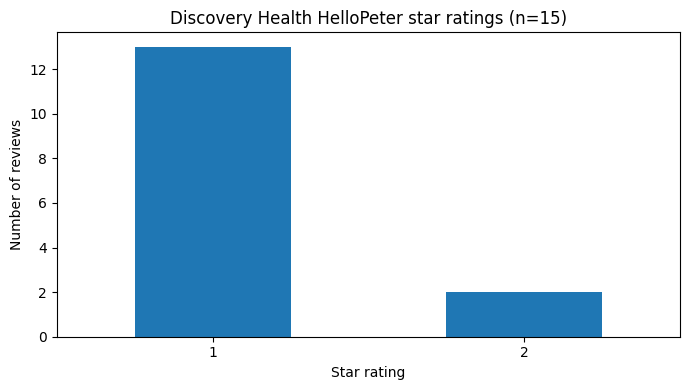

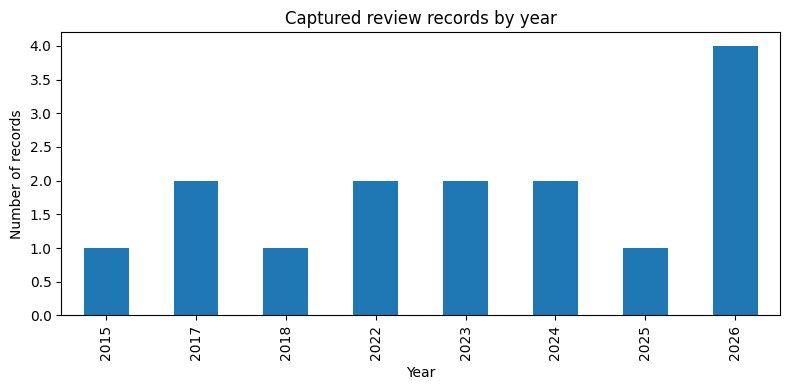

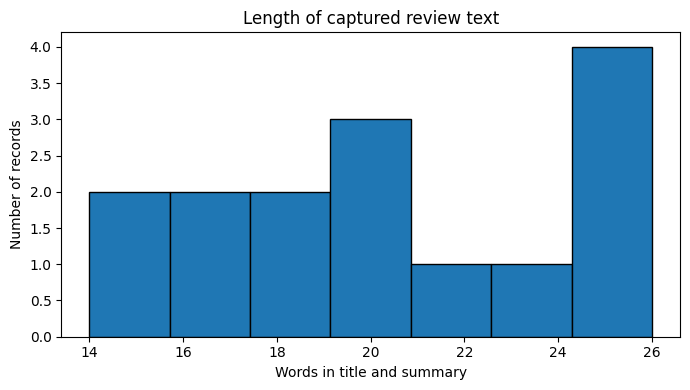

,Review_ID,Review_Date,Rating,Text_Word_Count
10,HP011,2015-08-18,2,17
14,HP015,2017-02-15,1,26
12,HP013,2017-11-01,2,22
13,HP014,2018-09-25,1,20
0,HP001,2022-11-08,1,24
5,HP006,2022-12-21,1,15
4,HP005,2023-07-04,1,19
11,HP012,2023-08-18,1,17
8,HP009,2024-04-26,1,20
9,HP010,2024-09-03,1,18


In [3]:
print("Rows and columns:", df.shape)
print("Date range:", df["Review_Date"].min().date(), "to", df["Review_Date"].max().date())
print("Mean rating:", round(df["Rating"].mean(), 2), "out of 5")
display(df[["Rating","Text_Word_Count"]].describe())

fig, ax = plt.subplots(figsize=(7,4))
df["Rating"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set(title="Discovery Health HelloPeter star ratings (n=15)", xlabel="Star rating", ylabel="Number of reviews")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8,4))
df.groupby(df["Review_Date"].dt.year).size().sort_index().plot(kind="bar", ax=ax)
ax.set(title="Captured review records by year", xlabel="Year", ylabel="Number of records")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7,4))
ax.hist(df["Text_Word_Count"], bins=7, edgecolor="black")
ax.set(title="Length of captured review text", xlabel="Words in title and summary", ylabel="Number of records")
plt.tight_layout(); plt.show()
display(df[["Review_ID","Review_Date","Rating","Text_Word_Count"]].sort_values("Review_Date"))

### EDA interpretation
The sample contains 15 reviews: 13 one-star and 2 two-star ratings (mean ≈ 1.13/5). Dates span 2015–2026. The sample is too small and irregular for reliable trend conclusions.

## 4. Identify broad areas of concern
Assign each review a primary complaint category and identify overlapping secondary themes.

Primary categories are analyst-coded from the available text. Secondary keyword tags may overlap; these are exploratory labels, not validated ground truth.

/tmp/ipykernel_754/758366388.py:27: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[safe_col] = df["Combined_Text"].str.lower().str.contains(pattern, regex=True)
/tmp/ipykernel_754/758366388.py:27: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[safe_col] = df["Combined_Text"].str.lower().str.contains(pattern, regex=True)
/tmp/ipykernel_754/758366388.py:27: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[safe_col] = df["Combined_Text"].str.lower().str.contains(pattern, regex=True)
/tmp/ipykernel_754/758366388.py:27: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[safe_col] = df["Combined_Text"].str.lower().str.contains(pattern, rege

,Number of reviews
Complaint_Category,
"Claims, benefits and exclusions",6
Customer service and communication,3
Hospital authorisation and care coordination,3
"Billing, premiums and membership",3


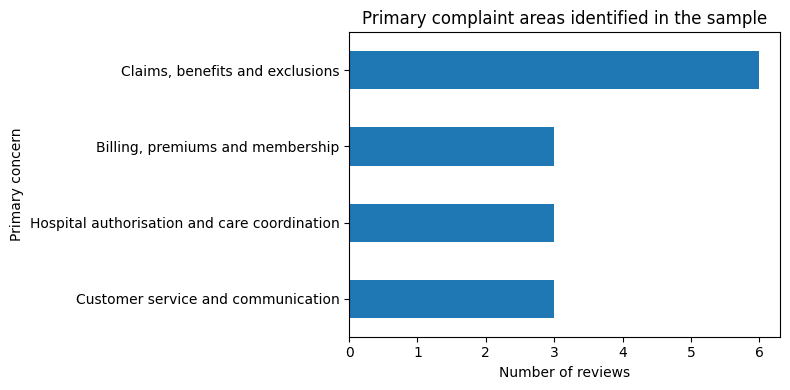

,Review_ID,Review_Title,Complaint_Category
0,HP001,Discovery health is the worse medical aid,"Claims, benefits and exclusions"
1,HP002,Customer help is waste of time,Customer service and communication
2,HP003,No compassion worst of the worst,Hospital authorisation and care coordination
3,HP004,Chronic Nightmare,"Claims, benefits and exclusions"
4,HP005,Leg not at full functionality,"Claims, benefits and exclusions"
5,HP006,Poor show,"Billing, premiums and membership"
6,HP007,Medical Aid Premium Increased Without Notification – Request for Refund,"Billing, premiums and membership"
7,HP008,WORST client service,Customer service and communication
8,HP009,Worse than momentum,"Claims, benefits and exclusions"
9,HP010,My PathCare results was not covered,"Claims, benefits and exclusions"


In [4]:
primary_map = {
    "HP001":"Claims, benefits and exclusions",
    "HP002":"Customer service and communication",
    "HP003":"Hospital authorisation and care coordination",
    "HP004":"Claims, benefits and exclusions",
    "HP005":"Claims, benefits and exclusions",
    "HP006":"Billing, premiums and membership",
    "HP007":"Billing, premiums and membership",
    "HP008":"Customer service and communication",
    "HP009":"Claims, benefits and exclusions",
    "HP010":"Claims, benefits and exclusions",
    "HP011":"Customer service and communication",
    "HP012":"Billing, premiums and membership",
    "HP013":"Hospital authorisation and care coordination",
    "HP014":"Hospital authorisation and care coordination",
    "HP015":"Claims, benefits and exclusions"
}
df["Complaint_Category"] = df["Review_ID"].map(primary_map).fillna("Other / unclear")
secondary_rules = {
    "Claims / cover / benefits": r"\b(claim|cover|covered|benefit|excluded|declined|procedure|implant|medication|doctor account|pathcare)\b",
    "Billing / premiums / membership": r"\b(premium|fee|membership|withdrawn|debit|refund|monthly payments|late.joining)\b",
    "Customer service / communication": r"\b(consultant|customer help|call.centre|wait|email|complaint|communication|human assistance|unanswered|rude|follow.up|chatbot)\b",
    "Hospital authorisation / care": r"\b(hospital|admission|authorisation|authorization|planned delivery|childbirth|care coordination)\b"
}
for label, pattern in secondary_rules.items():
    safe_col = "Tag_" + re.sub(r"[^A-Za-z]+","_",label).strip("_")
    df[safe_col] = df["Combined_Text"].str.lower().str.contains(pattern, regex=True)

category_counts = df["Complaint_Category"].value_counts()
display(category_counts.to_frame("Number of reviews"))
fig, ax = plt.subplots(figsize=(8,4))
category_counts.sort_values().plot(kind="barh", ax=ax)
ax.set(title="Primary complaint areas identified in the sample", xlabel="Number of reviews", ylabel="Primary concern")
plt.tight_layout(); plt.show()
display(df[["Review_ID","Review_Title","Complaint_Category"]])

### Concern-area interpretation
Claims/benefits/exclusions account for 6 records. Billing/membership, customer service/communication and hospital authorisation/care coordination account for 3 records each. These counts describe this sample only.

## 5. Frequent words and phrases
Count common unigrams and bigrams to identify recurring language.

,term,frequency
0,covered,4
1,hospital,4
2,payment,4
3,chronic,3
4,declined,3
5,despite,3
6,membership,3
7,plan,3
8,poor,3
9,procedure,3


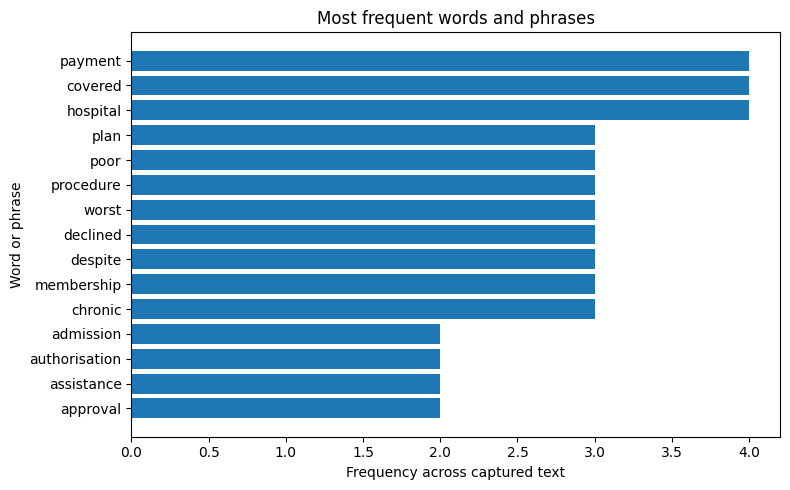

In [5]:
# Count unigrams and bigrams. Generic summary-attribution words are excluded from interpretation.
count_vec = CountVectorizer(stop_words="english", ngram_range=(1,2),
                            token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
count_matrix = count_vec.fit_transform(df["Combined_Text"].str.lower())
vocabulary = np.array(count_vec.get_feature_names_out())
frequencies = np.asarray(count_matrix.sum(axis=0)).ravel()
word_frequency = pd.DataFrame({"term":vocabulary, "frequency":frequencies})
summary_words = {"reviewer","says","reports","describes","complains","complain","review","discovery","health","medical","aid"}
word_frequency = word_frequency[
    ~word_frequency["term"].isin(summary_words) &
    ~word_frequency["term"].str.split().apply(lambda ws:any(w in summary_words for w in ws))
].sort_values(["frequency","term"], ascending=[False,True]).reset_index(drop=True)
display(word_frequency.head(20))
top = word_frequency.head(15).sort_values("frequency")
fig, ax = plt.subplots(figsize=(8,5))
ax.barh(top["term"], top["frequency"])
ax.set(title="Most frequent words and phrases", xlabel="Frequency across captured text", ylabel="Word or phrase")
plt.tight_layout(); plt.show()

### Word-frequency interpretation
Frequent terms point to topics such as cover, hospital, payments, medication and membership. Frequency alone does not measure seriousness or prevalence.

## 6. TF-IDF feature extraction
Convert review text into unigram and bigram features.

In [6]:
documents = df["Combined_Text"].tolist()
vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1,2),
                             max_features=60, sublinear_tf=True)
X = vectorizer.fit_transform(documents)
tfidf_terms = np.array(vectorizer.get_feature_names_out())
print("TF-IDF matrix shape:", X.shape)
print("Vocabulary size:", len(tfidf_terms))
display(pd.DataFrame({"TF-IDF feature":tfidf_terms}).head(30))

TF-IDF matrix shape: (15, 60)
Vocabulary size: 60


,TF-IDF feature
0,admission
1,aid
2,approval
3,assistance
4,authorisation
5,chronic
6,coastal
7,complains
8,cover
9,covered


### Feature selection
A supervised feature-selection method is unsuitable because the sentiment target has only one class. TF-IDF vocabulary limits are used to control dimensionality and reduce common-word noise.

## 7. K-means training and evaluation
Compare cluster numbers and TF-IDF settings using silhouette and Davies–Bouldin scores.

,Configuration,k,Features,Silhouette,Davies_Bouldin
0,unigrams_30,4,30,0.124000,1.647452
1,unigrams_30,3,30,0.109360,1.853115
2,unigrams_bigrams_60,4,60,0.095994,1.746061
3,unigrams_bigrams_60,3,60,0.093785,1.864487
4,unigrams_30,2,30,0.073242,2.467259
5,unigrams_bigrams_100,3,100,0.065744,2.072654
6,unigrams_bigrams_100,4,100,0.065037,1.888829
7,unigrams_bigrams_60,2,60,0.065016,2.493434
8,unigrams_bigrams_100,2,100,0.045242,2.724193


Selected configuration: ('unigrams_30', 4)
Silhouette: 0.124
Davies-Bouldin: 1.6475


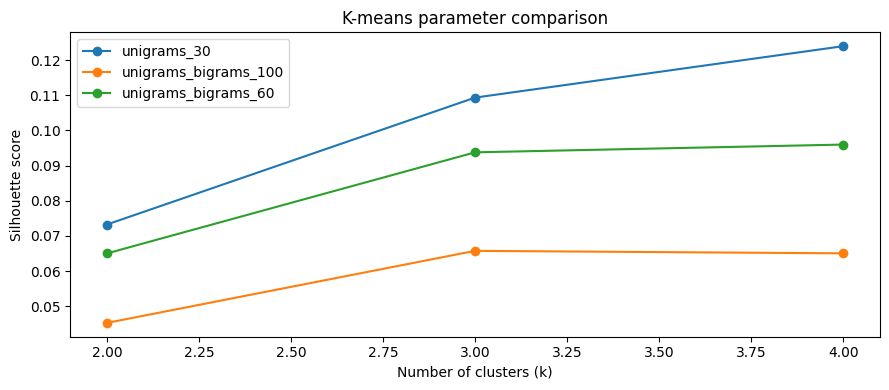

In [7]:
configurations = [
    {"name":"unigrams_30","ngram_range":(1,1),"max_features":30},
    {"name":"unigrams_bigrams_60","ngram_range":(1,2),"max_features":60},
    {"name":"unigrams_bigrams_100","ngram_range":(1,2),"max_features":100}
]
comparison = []
trained = {}
for cfg in configurations:
    vec = TfidfVectorizer(stop_words="english", ngram_range=cfg["ngram_range"],
                          max_features=cfg["max_features"], sublinear_tf=True)
    matrix = vec.fit_transform(documents)
    for k in [2,3,4]:
        km = KMeans(n_clusters=k, random_state=42, n_init=30)
        cluster_labels = km.fit_predict(matrix)
        sil = silhouette_score(matrix, cluster_labels)
        db = davies_bouldin_score(matrix.toarray(), cluster_labels)
        comparison.append({"Configuration":cfg["name"], "k":k,
                           "Features":matrix.shape[1], "Silhouette":sil,
                           "Davies_Bouldin":db})
        trained[(cfg["name"],k)] = (vec,matrix,km,cluster_labels)

comparison_df = pd.DataFrame(comparison).sort_values(
    ["Silhouette","Davies_Bouldin"], ascending=[False,True]
).reset_index(drop=True)
display(comparison_df)
best_row = comparison_df.iloc[0]
best_key = (best_row["Configuration"], int(best_row["k"]))
best_vec, best_matrix, best_model, best_labels = trained[best_key]
df["Cluster"] = best_labels
print("Selected configuration:", best_key)
print("Silhouette:", round(float(best_row["Silhouette"]),4))
print("Davies-Bouldin:", round(float(best_row["Davies_Bouldin"]),4))

fig, ax = plt.subplots(figsize=(9,4))
for config_name, group in comparison_df.groupby("Configuration"):
    group = group.sort_values("k")
    ax.plot(group["k"], group["Silhouette"], marker="o", label=config_name)
ax.set(title="K-means parameter comparison", xlabel="Number of clusters (k)", ylabel="Silhouette score")
ax.legend()
plt.tight_layout(); plt.show()

### Cluster interpretation
The best silhouette score is approximately 0.124, which indicates weak cluster separation. Inspect top terms and review membership; treat clusters as exploratory only.

In [8]:
best_terms = np.array(best_vec.get_feature_names_out())
for cluster_id, centre in enumerate(best_model.cluster_centers_):
    top_idx = centre.argsort()[::-1][:10]
    print(f"Cluster {cluster_id} strongest terms:", ", ".join(best_terms[top_idx]))
print("\nCluster sizes:")
display(df["Cluster"].value_counts().sort_index().to_frame("Records"))
print("\nRecords within clusters:")
display(df[["Review_ID","Review_Title","Complaint_Category","Cluster"]].sort_values(["Cluster","Review_ID"]))

Cluster 0 strongest terms: covered, despite, says, reviewer, membership, procedure, declined, reports, coastal, plan
Cluster 1 strongest terms: hospital, worst, describes, reports, admission, plan, reviewer, coastal, medication, cover
Cluster 2 strongest terms: chronic, complains, assistance, human, payment, reviewer, poor, medication, says, plan
Cluster 3 strongest terms: medical, aid, reviewer, cover, membership, says, declined, follow, refund, notification

Cluster sizes:


,Records
Cluster,
0,4
1,4
2,3
3,4



Records within clusters:


,Review_ID,Review_Title,Complaint_Category,Cluster
4,HP005,Leg not at full functionality,"Claims, benefits and exclusions",0
9,HP010,My PathCare results was not covered,"Claims, benefits and exclusions",0
11,HP012,membership withdrawal,"Billing, premiums and membership",0
14,HP015,"Covered for cochlear, but approval declined","Claims, benefits and exclusions",0
2,HP003,No compassion worst of the worst,Hospital authorisation and care coordination,1
7,HP008,WORST client service,Customer service and communication,1
12,HP013,Hospital Claims,Hospital authorisation and care coordination,1
13,HP014,Stay away from The Smart Classic Plan,Hospital authorisation and care coordination,1
1,HP002,Customer help is waste of time,Customer service and communication,2
3,HP004,Chronic Nightmare,"Claims, benefits and exclusions",2


## 9. Customer sentiment analysis
TextBlob calculates polarity (-1 to +1) and subjectivity (0 to 1) from the available review wording.

Polarity thresholds used: below -0.10 = Negative; above +0.10 = Positive; otherwise Neutral/mixed. These are analytical cut-offs, not universal standards. Because some text is summarised, scores may not reflect the original customer's tone.

Text-derived sentiment distribution:


,Records
Text_Sentiment,
Negative,5
Neutral / mixed,7
Positive,3


Mean polarity: -0.131
Mean subjectivity: 0.368


,Review_ID,Rating,Sentiment_Label,Text_Polarity,Text_Subjectivity,Text_Sentiment
0,HP001,1,Negative,-0.050000,0.500000,Neutral / mixed
1,HP002,1,Negative,0.043750,0.143750,Neutral / mixed
2,HP003,1,Negative,-0.625000,0.675000,Negative
3,HP004,1,Negative,-0.100000,0.200000,Neutral / mixed
4,HP005,1,Negative,0.116667,0.516667,Positive
5,HP006,1,Negative,-0.188889,0.255556,Negative
6,HP007,1,Negative,0.000000,0.000000,Neutral / mixed
7,HP008,1,Negative,-1.000000,1.000000,Negative
8,HP009,1,Negative,-0.300000,0.433333,Negative
9,HP010,1,Negative,0.000000,0.000000,Neutral / mixed


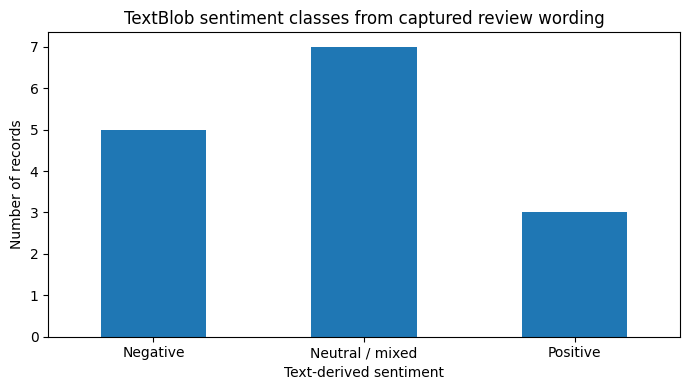

In [9]:
df["Text_Polarity"] = df["Combined_Text"].apply(lambda text: TextBlob(text).sentiment.polarity)
df["Text_Subjectivity"] = df["Combined_Text"].apply(lambda text: TextBlob(text).sentiment.subjectivity)

def sentiment_class(score):
    if score < -0.10:
        return "Negative"
    if score > 0.10:
        return "Positive"
    return "Neutral / mixed"

df["Text_Sentiment"] = df["Text_Polarity"].apply(sentiment_class)
sentiment_order = ["Negative","Neutral / mixed","Positive"]
text_sentiment_counts = df["Text_Sentiment"].value_counts().reindex(sentiment_order, fill_value=0)
print("Text-derived sentiment distribution:")
display(text_sentiment_counts.to_frame("Records"))
print("Mean polarity:", round(df["Text_Polarity"].mean(),3))
print("Mean subjectivity:", round(df["Text_Subjectivity"].mean(),3))
display(df[["Review_ID","Rating","Sentiment_Label","Text_Polarity","Text_Subjectivity","Text_Sentiment"]])
fig, ax = plt.subplots(figsize=(7,4))
text_sentiment_counts.plot(kind="bar",ax=ax)
ax.set(title="TextBlob sentiment classes from captured review wording",
       xlabel="Text-derived sentiment",ylabel="Number of records")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### Overall sentiment interpretation
Compare TextBlob scores with supplied labels and ratings. A positive or neutral score for a summary does not mean the original customer was satisfied; all supplied labels remain Negative.

Text_Sentiment,Negative,Neutral / mixed,Positive
Complaint_Category,,,
"Billing, premiums and membership",1,2,0
"Claims, benefits and exclusions",1,4,1
Customer service and communication,2,1,0
Hospital authorisation and care coordination,1,0,2


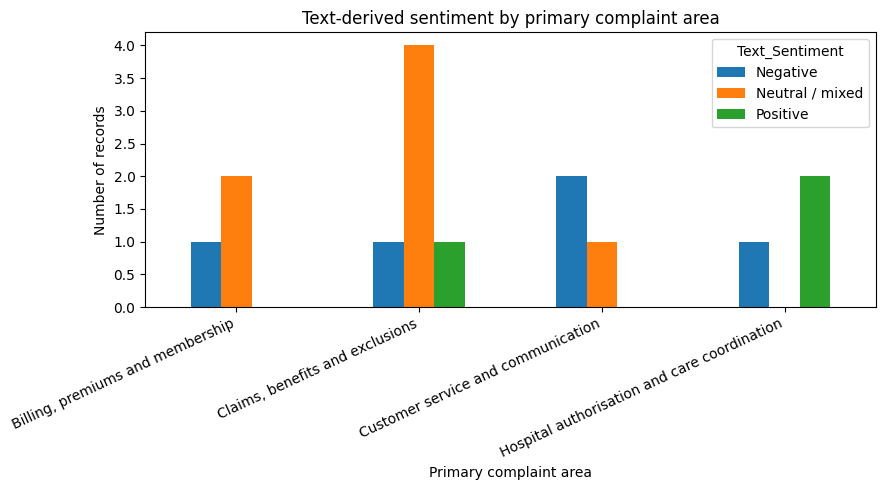

,Records,Mean_Polarity,Median_Polarity
Complaint_Category,,,
"Billing, premiums and membership",3,-0.062963,0.000000
"Claims, benefits and exclusions",6,-0.038889,-0.025000
Customer service and communication,3,-0.439583,-0.362500
Hospital authorisation and care coordination,3,-0.075397,0.190476


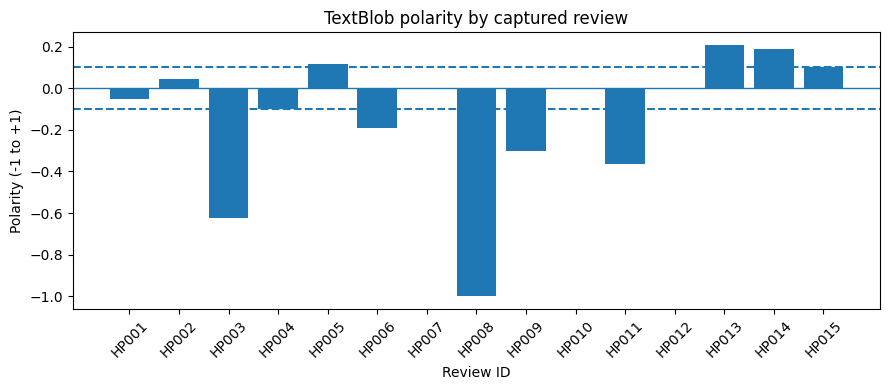

In [10]:
sentiment_category_table = pd.crosstab(
    df["Complaint_Category"], df["Text_Sentiment"]
).reindex(columns=sentiment_order, fill_value=0)
display(sentiment_category_table)
ax = sentiment_category_table.plot(kind="bar", figsize=(9,5))
ax.set(title="Text-derived sentiment by primary complaint area",
       xlabel="Primary complaint area",ylabel="Number of records")
plt.xticks(rotation=25,ha="right"); plt.tight_layout(); plt.show()

polarity_by_category = df.groupby("Complaint_Category")["Text_Polarity"].agg(
    Records="count", Mean_Polarity="mean", Median_Polarity="median"
)
display(polarity_by_category)
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(df["Review_ID"],df["Text_Polarity"])
ax.axhline(0,linewidth=1); ax.axhline(.10,linestyle="--"); ax.axhline(-.10,linestyle="--")
ax.set(title="TextBlob polarity by captured review",xlabel="Review ID",ylabel="Polarity (-1 to +1)")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

### Sentiment by complaint category
Compare polarity groups across primary complaint categories. Small group sizes prevent reliable ranking of service areas. Accuracy, precision, recall, F1 and ROC-AUC are not reported because there is no balanced labelled target.

## 12. Model improvement
Review the alternative TF-IDF settings and K-means configurations; retain the least weak setting only for exploratory inspection.

The best tested configuration used 30 unigram features and k=4 (silhouette ≈ 0.124; Davies–Bouldin ≈ 1.647). This is an improvement over the earlier setting, but separation remains weak. The model is not production-ready.